# Global World Bank & Cyber Incident Rate Spearman Analysis (2014–2024)

Cross-country panel analysis integrating **World Bank WDI** macroeconomic/digital indicators (including **New business density**, `IC.BUS.NDNS.ZS`) with **UMD Cyber Events** normalized as the primary incident rate (**incidents per 100,000 residents**, using World Bank `SP.POP.TOTL`).

- **Unit of observation:** Sovereign country × year (`country_iso3 × year`).
- **Correlation window:** `2014–2024` (year `2025` is excluded from cross-indicator heatmaps because World Bank `IC.BUS.NDNS.ZS` and `IT.NET.BBND.P2` have `0` reported countries in 2025, and `IT.NET.USER.ZS` has only `10`).


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

PROJECT_ROOT = Path(r"d:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany")
if str(PROJECT_ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

PANEL_PATH = PROJECT_ROOT / "data" / "prepared" / "global_country_year_wb_umd.csv"
WB_RAW_PATH = PROJECT_ROOT / "data" / "raw" / "world_bank_global_2014_2025.csv"

if not PANEL_PATH.exists() or not WB_RAW_PATH.exists():
    from build_global_wb_panel import build_global_datasets
    build_global_datasets()

panel_all = pd.read_csv(PANEL_PATH)
wb_raw = pd.read_csv(WB_RAW_PATH)

# Use 2014-2024 where all 9 WB features have strong cross-country coverage
panel = panel_all[panel_all["year"].between(2014, 2024)].copy()
panel_1m = panel[panel["population"] >= 1_000_000].copy()

FEATURE_LABELS = {
    "gdp_per_capita_usd": "GDP per capita",
    "gdp_growth_pct": "GDP growth",
    "industry_gdp_pct": "Industry (% GDP)",
    "services_gdp_pct": "Services (% GDP)",
    "unemployment_rate_pct": "Unemployment rate",
    "labor_participation_pct": "Labor participation",
    "new_business_density": "New business density",
    "internet_users_pct": "Internet users (%)",
    "broadband_per_100": "Broadband per 100",
}
ALL_MATRIX_LABELS = {"incidents_per_100k": "Incidents per 100k", **FEATURE_LABELS}

print(
    f"2014-2024 panel: {len(panel):,} rows across {panel['country_iso3'].nunique()} sovereign countries | "
    f"Matched UMD incidents: {int(panel['incident_count'].sum()):,}"
)
print(
    f"Population >= 1M subset: {len(panel_1m):,} rows across {panel_1m['country_iso3'].nunique()} countries | "
    f"Matched UMD incidents: {int(panel_1m['incident_count'].sum()):,}"
)


2014-2024 panel: 2,387 rows across 217 sovereign countries | Matched UMD incidents: 14,276
Population >= 1M subset: 1,760 rows across 160 countries | Matched UMD incidents: 14,197


### Feature Definitions (World Bank WDI Indicators & Incident Metrics)

| Column (WB Code) | Label in Charts | Meaning |
|---|---|---|
| `population` (`SP.POP.TOTL`) | – | Total resident population of the country in a given year, used as the denominator to normalize incident counts. |
| `gdp_per_capita_usd` (`NY.GDP.PCAP.CD`) | GDP per capita | Gross domestic product per resident in current US dollars, measuring overall economic output per person. |
| `gdp_growth_pct` (`NY.GDP.MKTP.KD.ZG`) | GDP growth | Annual percentage growth rate of real GDP at constant prices, capturing short-term macroeconomic momentum. |
| `industry_gdp_pct` (`NV.IND.TOTL.ZS`) | Industry (% GDP) | Value added by the industrial sector (including manufacturing and construction) as a percentage of total GDP. |
| `services_gdp_pct` (`NV.SRV.TOTL.ZS`) | Services (% GDP) | Value added by the services sector as a percentage of total GDP. |
| `unemployment_rate_pct` (`SL.UEM.TOTL.ZS`) | Unemployment rate | Percentage of the total labor force that is without work but available for and actively seeking employment. |
| `labor_participation_pct` (`SL.TLF.CACT.ZS`) | Labor participation | Percentage of the population aged 15 and older that is economically active in the labor force. |
| `new_business_density` (`IC.BUS.NDNS.ZS`) | New business density | Number of newly registered corporations per 1,000 working-age residents (ages 15–64). |
| `internet_users_pct` (`IT.NET.USER.ZS`) | Internet users (%) | Percentage of individuals in the country's population who use the Internet. |
| `broadband_per_100` (`IT.NET.BBND.P2`) | Broadband per 100 | Number of fixed broadband Internet subscriptions per 100 inhabitants. |
| `incident_count` | – | Total number of publicly documented UMD cyber incidents attributed to the country in that year. |
| `incidents_per_100k` | Incidents per 100k | Population-normalized cyber incident rate computed in `build_global_wb_panel.py` as `incident_count / population * 100,000`. |


## 1. Economic Indicators and Cyber Incident Rates — Pooled Spearman Matrix (2014–2024)

Full pairwise Spearman rank correlation matrix across all country-year observations (`2014–2024`)

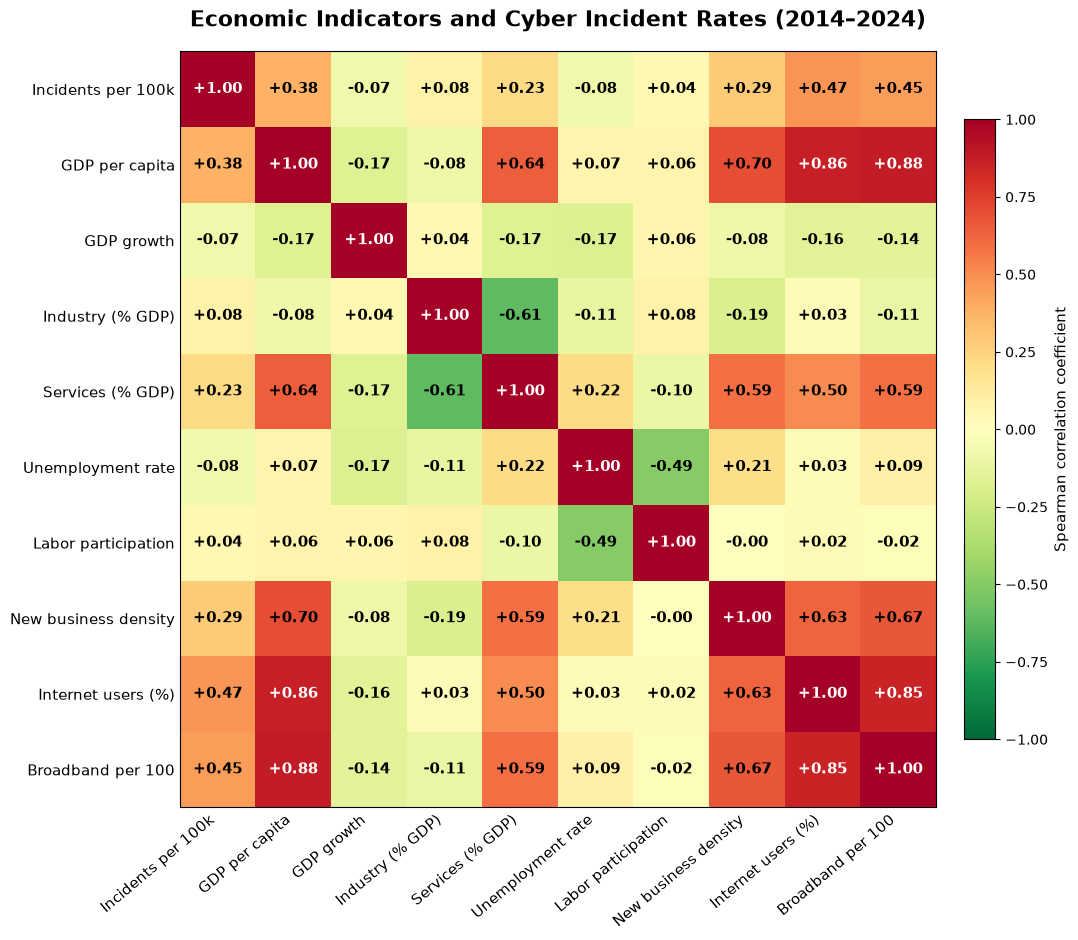

,All sovereign countries,Countries pop >= 1M
Internet users (%),0.472,0.577
Broadband per 100,0.452,0.599
GDP per capita,0.382,0.595
New business density,0.287,0.389
Services (% GDP),0.225,0.446
Industry (% GDP),0.084,-0.058
Labor participation,0.041,0.031
GDP growth,-0.072,-0.134
Unemployment rate,-0.078,-0.053


In [2]:
cols = list(ALL_MATRIX_LABELS.keys())
corr_matrix = (
    panel[cols]
    .corr(method="spearman")
    .rename(index=ALL_MATRIX_LABELS, columns=ALL_MATRIX_LABELS)
)

fig, ax = plt.subplots(figsize=(11.5, 9.5))
cmap = plt.get_cmap("RdYlGn_r").copy()
im = ax.imshow(corr_matrix.values, cmap=cmap, vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=40, ha="right", fontsize=11)
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_yticklabels(corr_matrix.index, fontsize=11)

for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        val = corr_matrix.iloc[i, j]
        ax.text(
            j,
            i,
            f"{val:+.2f}",
            ha="center",
            va="center",
            fontsize=10.5,
            fontweight="bold",
            color="white" if abs(val) >= 0.70 else "black",
        )

ax.set_title(
    "Economic Indicators and Cyber Incident Rates (2014–2024)",
    fontsize=16,
    fontweight="bold",
    pad=18,
)
cbar = fig.colorbar(im, ax=ax, shrink=0.82, pad=0.03)
cbar.set_label("Spearman correlation coefficient", fontsize=11)
ax.tick_params(length=0)

plt.tight_layout()
plt.show()

# Print sensitivity comparison: all 217 countries vs population >= 1M
corr_1m_target = (
    panel_1m[cols]
    .corr(method="spearman")["incidents_per_100k"]
    .drop("incidents_per_100k")
)
comp = pd.DataFrame({
    "All sovereign countries": corr_matrix.loc[list(FEATURE_LABELS.values()), "Incidents per 100k"],
    "Countries pop >= 1M": corr_1m_target.rename(index=FEATURE_LABELS),
}).round(3)
display(comp.sort_values("All sovereign countries", ascending=False))


## 2. Annual Economic Correlations with Cyber Incident Rates (2014–2024)

Each row computes cross-country Spearman rank correlations against `Incidents per 100k` within that individual year (`2014` through `2024`), testing whether associations persist over time or shift across periods.


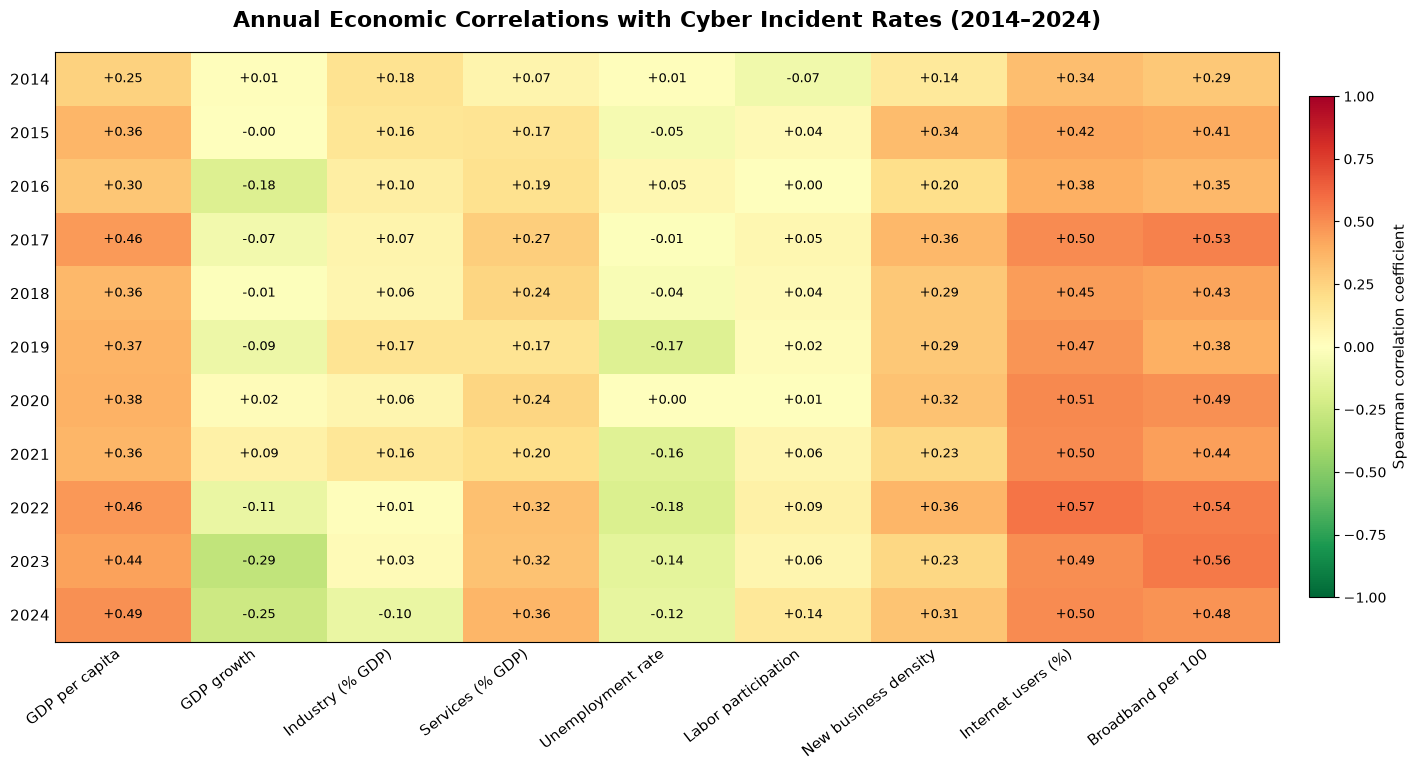

In [3]:
annual_rows = []
for yr, grp in panel.groupby("year"):
    c = grp[list(FEATURE_LABELS.keys()) + ["incidents_per_100k"]].corr(method="spearman")[
        "incidents_per_100k"
    ]
    annual_rows.append({"year": int(yr), **{lbl: c[col] for col, lbl in FEATURE_LABELS.items()}})

annual_df = pd.DataFrame(annual_rows).set_index("year")

fig, ax = plt.subplots(figsize=(15.5, 7.8))
im = ax.imshow(
    annual_df.values,
    cmap="RdYlGn_r",
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
    aspect="auto",
)

ax.set_xticks(range(len(annual_df.columns)))
ax.set_xticklabels(annual_df.columns, rotation=38, ha="right", fontsize=11)
ax.set_yticks(range(len(annual_df.index)))
ax.set_yticklabels(annual_df.index, fontsize=11)

for i in range(len(annual_df.index)):
    for j in range(len(annual_df.columns)):
        val = annual_df.iloc[i, j]
        ax.text(
            j,
            i,
            f"{val:+.2f}",
            ha="center",
            va="center",
            fontsize=9.5,
            color="white" if abs(val) >= 0.70 else "black",
        )

ax.set_title(
    "Annual Economic Correlations with Cyber Incident Rates (2014–2024)",
    fontsize=16,
    fontweight="bold",
    pad=18,
)
cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("Spearman correlation coefficient", fontsize=11)
ax.tick_params(length=0)

plt.tight_layout()
plt.show()


## 3. Germany (`DEU`) vs. Global Sovereign Benchmark (2014–2024)

Side-by-side view of how **Germany** (`DEU`) compares against the **World aggregate (`WLD` / country median)** on the primary UMD incident rate (`incidents_per_100k`) and **New business density** (`IC.BUS.NDNS.ZS`), plus where Germany sits relative to the Population ≥ 1M sensitivity check.


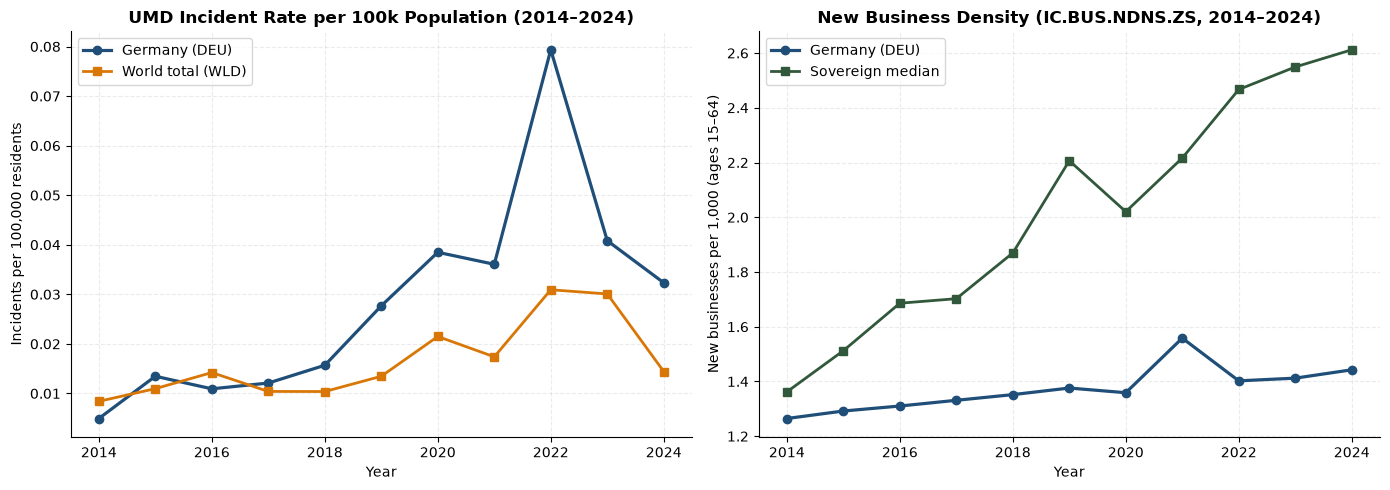

,year,incident_count,incidents_per_100k,gdp_per_capita_usd,new_business_density,internet_users_pct,broadband_per_100,wld_incidents_per_100k
600,2014,4,0.005,48959.599,1.265,86.194,36.341,0.008
601,2015,11,0.013,41929.755,1.292,87.590,37.413,0.011
602,2016,9,0.011,42948.938,1.310,84.165,38.499,0.014
603,2017,10,0.012,45553.934,1.331,84.394,39.989,0.010
604,2018,13,0.016,48916.169,1.352,87.037,40.965,0.010
605,2019,23,0.028,47656.200,1.376,88.135,42.116,0.013
606,2020,32,0.038,47394.873,1.359,89.813,43.305,0.021
607,2021,30,0.036,52349.246,1.558,91.431,44.064,0.017
608,2022,66,0.079,50506.518,1.402,91.630,44.619,0.031
609,2023,34,0.041,54776.767,1.412,92.476,45.381,0.030


In [4]:
deu = panel[panel["country_iso3"] == "DEU"].sort_values("year")
wld_pop = wb_raw[(wb_raw["country_iso3"] == "WLD") & (wb_raw["year"].between(2014, 2024))].sort_values("year")
global_inc = panel.groupby("year", as_index=False)["incident_count"].sum().merge(
    wld_pop[["year", "population", "new_business_density"]], on="year", how="left"
)
global_inc["wld_incidents_per_100k"] = global_inc["incident_count"] / global_inc["population"] * 100_000
med_nbd = panel.groupby("year")["new_business_density"].median().reset_index(name="median_nbd")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Incident rate DEU vs World aggregate (UMD)
axes[0].plot(deu["year"], deu["incidents_per_100k"], marker="o", linewidth=2.3, color="#1F4E78", label="Germany (DEU)")
axes[0].plot(global_inc["year"], global_inc["wld_incidents_per_100k"], marker="s", linewidth=2.0, color="#D97706", label="World total (WLD)")
axes[0].set_title("UMD Incident Rate per 100k Population (2014–2024)", fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Incidents per 100,000 residents")
axes[0].set_xticks(range(2014, 2025, 2))
axes[0].grid(alpha=0.25, linestyle="--")
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].legend()

# Right: New business density DEU vs World / Country Median
axes[1].plot(deu["year"], deu["new_business_density"], marker="o", linewidth=2.3, color="#1F4E78", label="Germany (DEU)")
axes[1].plot(med_nbd["year"], med_nbd["median_nbd"], marker="s", linewidth=2.0, color="#31583B", label="Sovereign median")
axes[1].set_title("New Business Density (IC.BUS.NDNS.ZS, 2014–2024)", fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("New businesses per 1,000 (ages 15–64)")
axes[1].set_xticks(range(2014, 2025, 2))
axes[1].grid(alpha=0.25, linestyle="--")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].legend()

plt.tight_layout()
plt.show()

summary_deu = deu[["year", "incident_count", "incidents_per_100k", "gdp_per_capita_usd", "new_business_density", "internet_users_pct", "broadband_per_100"]].copy()
summary_deu["wld_incidents_per_100k"] = global_inc["wld_incidents_per_100k"].values
display(summary_deu.round(3))


## 4. Sensitivity Check — Germany Only: `UMD` vs. Combined DE Dataset (2,323 Incidents)

In Sections 1–2, Spearman correlations measure **cross-country differences** across `217` sovereign countries. Here we isolate **Germany (`DEU`) alone across `n = 11` years (`2014–2024`)** and test how much the correlation changes when replacing Germany's single global source (`UMD`: `259` incidents in 2014–2024) with the full deduplicated German dataset ([germany_large_incidents.csv]): `2,323` incidents total, `1,324` in 2014–2024).

### What happens and why it must be interpreted carefully
1. **Correlations jump sharply with the combined DE dataset** (e.g., `Broadband per 100` rises from `+0.86` to **`+0.97`**, `New business density` from `+0.80` to **`+0.91`**, and `GDP per capita` from `+0.55` to **`+0.72`**).
2. **Spurious time-trend effect (`n = 11` annual points):** Inside one country over just 11 consecutive years, structural indicators such as `Broadband per 100`, `Internet users (%)`, `New business density`, and `Services (% GDP)` trend monotonically upward. Any incident series that climbs year after year automatically gets `+0.89` to `+0.97` rank correlation—even without a causal link.
3. **The 2021 coverage break:** `UMD` in Germany peaks in `2022` (`66`) and drops in `2023–2024` (`34 → 27`). By contrast, the combined DE dataset jumps from `35` (`2020`) to `140` (`2021`), `272` (`2022`), `421` (`2023`), and `363` (`2024`), largely because **KonBriefing starts in 2021** (`0 → 102`) and **Ransomware.live** accelerates rapidly from 2022 onward—making the combined curve track upward-trending World Bank series even more tightly.
4. **Raw count vs. per-100k inside Germany:** Because Germany's population changes slowly relative to annual incident jumps, `combined_de_incidents` and `combined_de_per_100k` produce the **exact same** Spearman correlation.


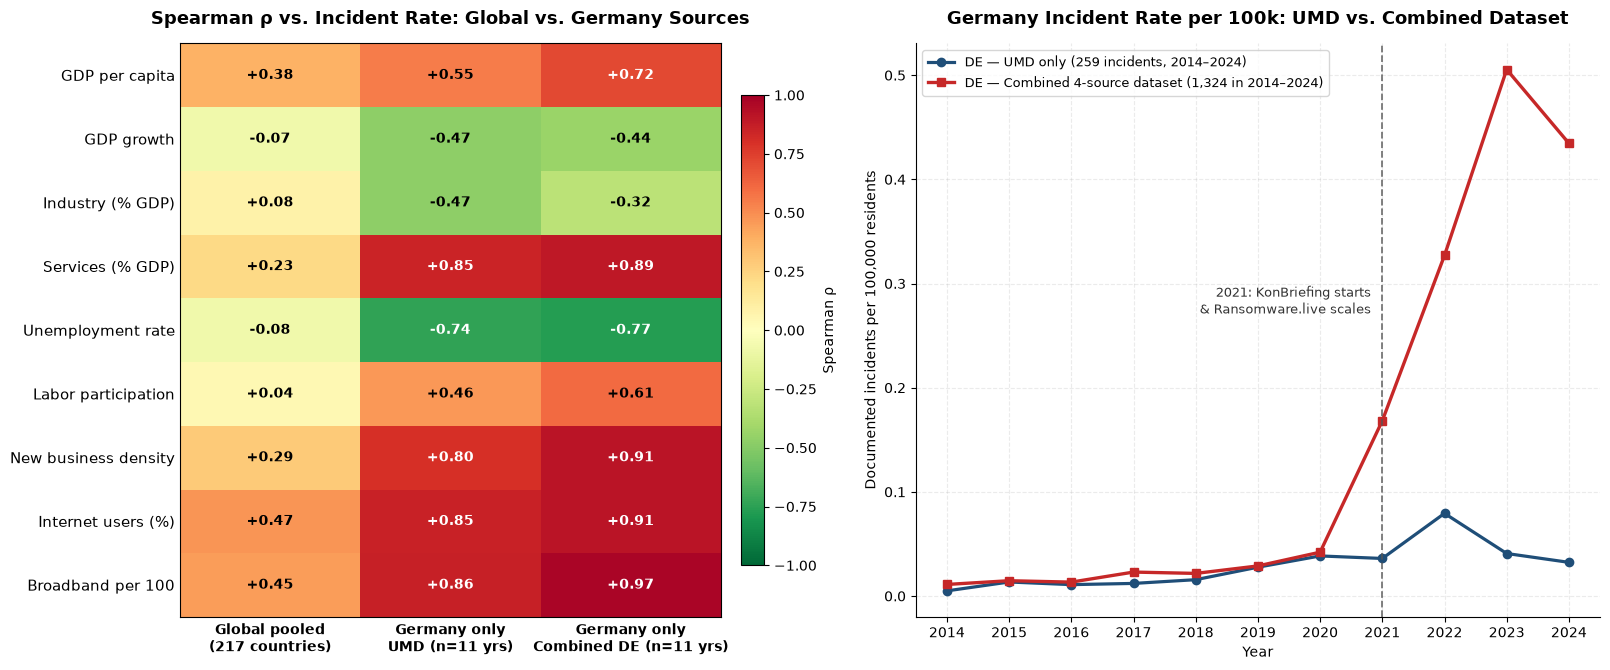

Full germany_large_incidents.csv rows: 2,323 | 2014-2024 subset: 1,324 vs UMD: 259


,Global pooled (n=217),DE UMD per 100k (n=11),DE Combined per 100k (n=11),Delta (DE Combined - DE UMD)
GDP per capita,0.382,0.555,0.718,0.164
GDP growth,-0.072,-0.473,-0.436,0.036
Industry (% GDP),0.084,-0.473,-0.318,0.155
Services (% GDP),0.225,0.845,0.891,0.045
Unemployment rate,-0.078,-0.736,-0.773,-0.036
Labor participation,0.041,0.464,0.609,0.145
New business density,0.287,0.800,0.909,0.109
Internet users (%),0.472,0.855,0.909,0.055
Broadband per 100,0.452,0.864,0.973,0.109


,year,de_umd_incidents,de_combined_incidents,de_umd_per_100k,de_combined_per_100k,new_business_density,broadband_per_100
0,2014,4,9,0.0049,0.0111,1.2648,36.3409
1,2015,11,12,0.0135,0.0147,1.2921,37.4127
2,2016,9,11,0.0109,0.0134,1.3104,38.4991
3,2017,10,19,0.0121,0.0230,1.3313,39.9888
4,2018,13,18,0.0157,0.0217,1.3520,40.9651
5,2019,23,24,0.0277,0.0289,1.3761,42.1156
6,2020,32,35,0.0385,0.0421,1.3590,43.3049
7,2021,30,140,0.0361,0.1683,1.5585,44.0643
8,2022,66,272,0.0793,0.3270,1.4024,44.6186
9,2023,34,421,0.0408,0.5055,1.4122,45.3805


In [5]:
DE_INC_PATH = PROJECT_ROOT / "data" / "prepared" / "germany_large_incidents.csv"
de_incidents_raw = pd.read_csv(DE_INC_PATH)

de_yearly_combined = (
    de_incidents_raw[de_incidents_raw["year"].between(2014, 2024)]
    .groupby("year", as_index=False)
    .size()
    .rename(columns={"size": "de_combined_incidents"})
)

deu_comp = (
    panel[panel["country_iso3"] == "DEU"]
    .sort_values("year")
    .merge(de_yearly_combined, on="year", how="left", validate="one_to_one")
)
deu_comp["de_combined_per_100k"] = (
    deu_comp["de_combined_incidents"] / deu_comp["population"] * 100_000
)

feat_cols = list(FEATURE_LABELS.keys())
feat_names = [FEATURE_LABELS[c] for c in feat_cols]

# 1) Global pooled cross-country (from Section 1)
rho_global = corr_matrix.loc[feat_names, "Incidents per 100k"].values

# 2) Germany only (n=11 yrs): UMD per 100k vs Combined DE dataset per 100k
de_corr = deu_comp[feat_cols + ["incidents_per_100k", "de_combined_per_100k"]].corr(
    method="spearman"
)
rho_de_umd = de_corr.loc[feat_cols, "incidents_per_100k"].values
rho_de_comb = de_corr.loc[feat_cols, "de_combined_per_100k"].values

comp_mat = pd.DataFrame(
    {
        "Global pooled\n(217 countries)": rho_global,
        "Germany only\nUMD (n=11 yrs)": rho_de_umd,
        "Germany only\nCombined DE (n=11 yrs)": rho_de_comb,
    },
    index=feat_names,
)

fig, axes = plt.subplots(
    1, 2, figsize=(16.2, 6.8), gridspec_kw={"width_ratios": [1.08, 1.12]}
)

# Left panel: 3-column Spearman comparison heatmap
im = axes[0].imshow(
    comp_mat.values,
    cmap="RdYlGn_r",
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
    aspect="auto",
)
axes[0].set_xticks(range(comp_mat.shape[1]))
axes[0].set_xticklabels(comp_mat.columns, fontsize=9.8, fontweight="bold")
axes[0].set_yticks(range(comp_mat.shape[0]))
axes[0].set_yticklabels(comp_mat.index, fontsize=10.5)
for i in range(comp_mat.shape[0]):
    for j in range(comp_mat.shape[1]):
        val = comp_mat.iloc[i, j]
        axes[0].text(
            j,
            i,
            f"{val:+.2f}",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="white" if abs(val) >= 0.70 else "black",
        )
axes[0].set_title(
    "Spearman ρ vs. Incident Rate: Global vs. Germany Sources",
    fontsize=13,
    fontweight="bold",
    pad=14,
)
axes[0].tick_params(length=0)
cbar = fig.colorbar(im, ax=axes[0], shrink=0.82, pad=0.03)
cbar.set_label("Spearman ρ", fontsize=10)

# Right panel: Why Germany correlations shift (trajectory comparison)
axes[1].plot(
    deu_comp["year"],
    deu_comp["incidents_per_100k"],
    marker="o",
    linewidth=2.3,
    color="#1F4E78",
    label="DE — UMD only (259 incidents, 2014–2024)",
)
axes[1].plot(
    deu_comp["year"],
    deu_comp["de_combined_per_100k"],
    marker="s",
    linewidth=2.4,
    color="#C62828",
    label="DE — Combined 4-source dataset (1,324 in 2014–2024)",
)
axes[1].axvline(2021, color="#555555", linestyle="--", linewidth=1.3, alpha=0.8)
axes[1].text(
    2020.82,
    deu_comp["de_combined_per_100k"].max() * 0.56,
    "2021: KonBriefing starts\n& Ransomware.live scales",
    fontsize=9.5,
    color="#333333",
    ha="right",
    va="center",
)
axes[1].set_title(
    "Germany Incident Rate per 100k: UMD vs. Combined Dataset",
    fontsize=13,
    fontweight="bold",
    pad=14,
)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Documented incidents per 100,000 residents")
axes[1].set_xticks(range(2014, 2025))
axes[1].grid(alpha=0.25, linestyle="--")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].legend(loc="upper left", fontsize=9.5)

plt.tight_layout()
plt.show()

print(
    f"Full germany_large_incidents.csv rows: {len(de_incidents_raw):,} | "
    f"2014-2024 subset: {int(deu_comp['de_combined_incidents'].sum()):,} vs UMD: {int(deu_comp['incident_count'].sum()):,}"
)
delta_table = pd.DataFrame(
    {
        "Global pooled (n=217)": rho_global,
        "DE UMD per 100k (n=11)": rho_de_umd,
        "DE Combined per 100k (n=11)": rho_de_comb,
        "Delta (DE Combined - DE UMD)": rho_de_comb - rho_de_umd,
    },
    index=feat_names,
).round(3)
display(delta_table)

display(
    deu_comp[
        [
            "year",
            "incident_count",
            "de_combined_incidents",
            "incidents_per_100k",
            "de_combined_per_100k",
            "new_business_density",
            "broadband_per_100",
        ]
    ]
    .rename(columns={"incident_count": "de_umd_incidents", "incidents_per_100k": "de_umd_per_100k"})
    .round(4)
)



## 5. Statistical Significance in Germany (2014–2024): Raw Levels vs. Detrended Changes (`.diff()`) with Benjamini–Hochberg Correction

In Section 4, several World Bank indicators showed very high Spearman correlations (`+0.80` to `+0.97`) with Germany's cyber incident rate over `n = 11` years (`2014–2024`). Here we test **which of those 9 correlations are statistically significant** and separate **true year-to-year co-movement** from **shared multi-year time trends**:

1. **Benjamini–Hochberg (BH) multiple-testing correction (`m = 9` tests, `alpha = 0.05`):** Testing 9 economic factors at once against the incident rate creates a `1 - 0.95^9 ≈ 37%` chance of at least one random false positive under the null hypothesis. BH controls the **False Discovery Rate (FDR)**—keeping the expected share of false positives among flagged results below `5%` (`q_bh < 0.05`) without discarding too much statistical power at small `n` like Bonferroni does.
2. **Removing the shared time trend with simple annual differences (`.diff()`):** Structural indicators (`Broadband per 100`, `Internet users (%)`, `Services (% GDP)`, `New business density`, and `Unemployment rate`) move almost monotonically over `2014–2024`, while reported cyber incidents also climb over time. Taking simple year-over-year differences (`Δx_t = x_t - x_{t-1}`, `n = 10` transitions) subtracts the shared time drift cleanly and tests whether years with sharper economic/digital shifts coincide with sharper incident jumps.

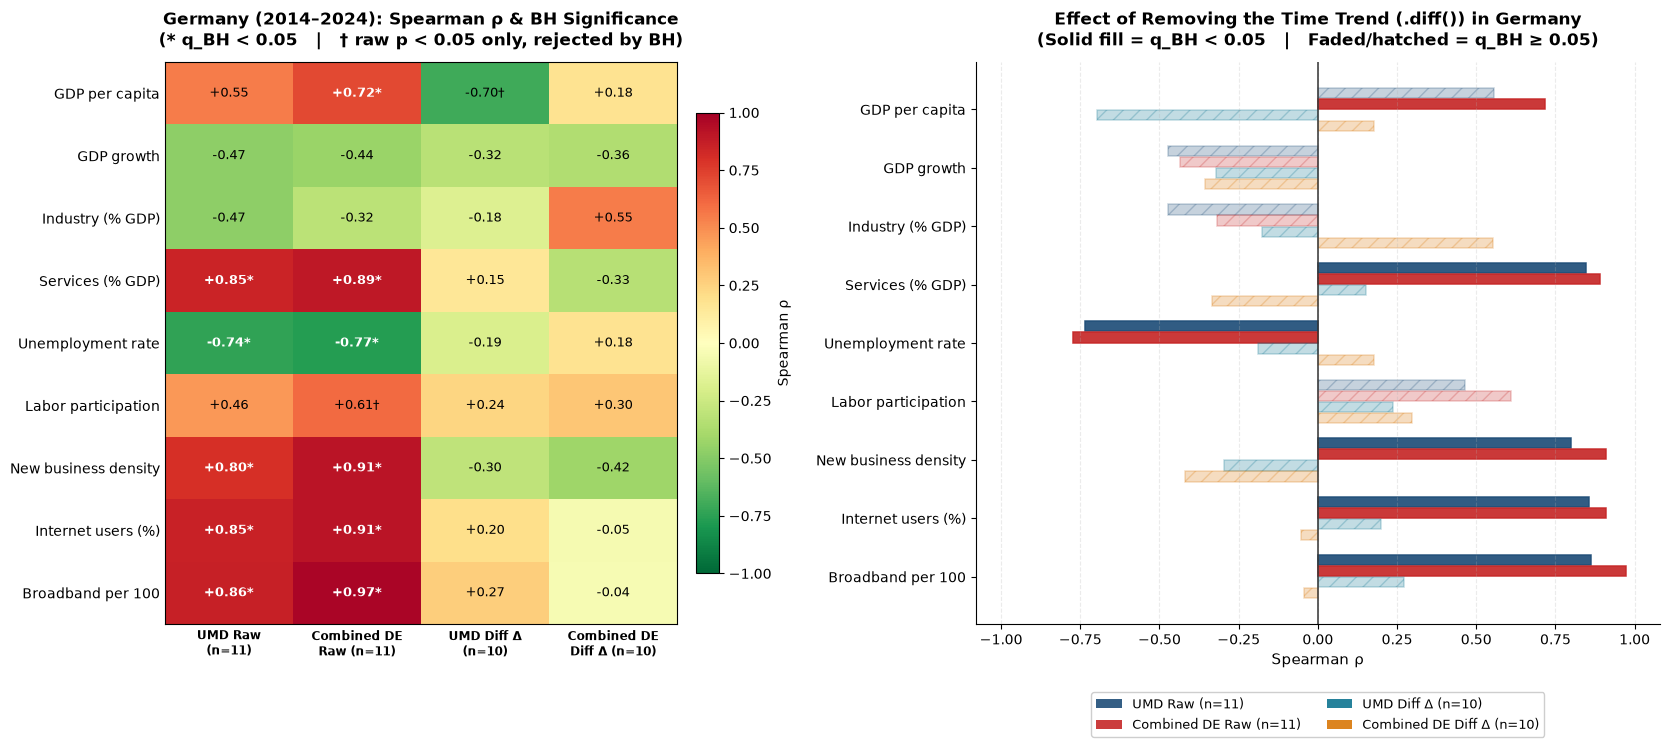

Significant correlations (alpha=0.05) -> UMD Raw: 5/9 raw, 5/9 BH | Comb DE Raw: 7/9 raw, 6/9 BH | UMD Diff: 1/9 raw, 0/9 BH | Comb DE Diff: 0/9 raw, 0/9 BH


,UMD Raw rho,UMD Raw p,UMD Raw q_BH,Comb Raw rho,Comb Raw p,Comb Raw q_BH,UMD Diff rho,UMD Diff p,UMD Diff q_BH,Comb Diff rho,Comb Diff p,Comb Diff q_BH
feature,,,,,,,,,,,,
GDP per capita,0.5545,0.0767,0.1150,0.7182,0.0128,0.0192,-0.6970,0.0251,0.2259,0.1758,0.6272,0.8064
GDP growth,-0.4727,0.1420,0.1509,-0.4364,0.1797,0.2021,-0.3212,0.3655,0.6761,-0.3576,0.3104,0.7285
Industry (% GDP),-0.4727,0.1420,0.1509,-0.3182,0.3403,0.3403,-0.1758,0.6272,0.6761,0.5515,0.0984,0.7285
Services (% GDP),0.8455,0.0010,0.0031,0.8909,0.0002,0.0005,0.1515,0.6761,0.6761,-0.3333,0.3466,0.7285
Unemployment rate,-0.7364,0.0098,0.0176,-0.7727,0.0053,0.0095,-0.1879,0.6032,0.6761,0.1758,0.6272,0.8064
Labor participation,0.4636,0.1509,0.1509,0.6091,0.0467,0.0600,0.2364,0.5109,0.6761,0.2970,0.4047,0.7285
New business density,0.8000,0.0031,0.0070,0.9091,0.0001,0.0003,-0.2970,0.4047,0.6761,-0.4182,0.2291,0.7285
Internet users (%),0.8545,0.0008,0.0031,0.9091,0.0001,0.0003,0.2000,0.5796,0.6761,-0.0545,0.8810,0.9074
Broadband per 100,0.8636,0.0006,0.0031,0.9727,0.0000,0.0000,0.2727,0.4458,0.6761,-0.0424,0.9074,0.9074


In [6]:
from scipy.stats import spearmanr, false_discovery_control


def compute_spearman_bh(df, target_col, feature_cols, feature_labels):
    """Compute Spearman rho, raw two-sided p-value, and BH-adjusted q-value across m features."""
    rows = []
    for col in feature_cols:
        # Pairwise rank correlation on complete pairs (safe even if subsets drop a year)
        sub = df[[target_col, col]].dropna()
        rho, p_raw = spearmanr(sub[target_col], sub[col])
        rows.append(
            {
                "feature_col": col,
                "feature": feature_labels[col],
                "n": len(sub),
                "rho": float(rho),
                "p_raw": float(p_raw),
            }
        )
    res = pd.DataFrame(rows)
    # Apply Benjamini-Hochberg FDR control across the m=9 tested economic indicators
    res["q_bh"] = false_discovery_control(res["p_raw"].to_numpy(), method="bh")
    res["sig_raw"] = res["p_raw"] < 0.05
    res["sig_bh"] = res["q_bh"] < 0.05
    return res.set_index("feature")


def plot_sig_heatmap(ax, rho_df, p_df, q_df, title):
    """Draw a Spearman correlation heatmap marking BH-significant (*) and raw-only (†) cells."""
    im = ax.imshow(
        rho_df.values,
        cmap="RdYlGn_r",
        norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
        aspect="auto",
    )
    ax.set_xticks(range(rho_df.shape[1]))
    ax.set_xticklabels(rho_df.columns, fontsize=8.6, fontweight="bold")
    ax.set_yticks(range(rho_df.shape[0]))
    ax.set_yticklabels(rho_df.index, fontsize=10.2)

    for i in range(rho_df.shape[0]):
        for j in range(rho_df.shape[1]):
            val = rho_df.iloc[i, j]
            q_val = q_df.iloc[i, j]
            p_val = p_df.iloc[i, j]
            # '*' = survives BH correction (q_bh < 0.05); '†' = raw p < 0.05 only (filtered out by BH)
            marker = "*" if q_val < 0.05 else ("†" if p_val < 0.05 else "")
            label = f"{val:+.2f}{marker}"
            ax.text(
                j,
                i,
                label,
                ha="center",
                va="center",
                fontsize=9.6,
                fontweight="bold" if q_val < 0.05 else "normal",
                color="white" if abs(val) >= 0.70 else "black",
            )
    ax.set_title(title, fontsize=12.5, fontweight="bold", pad=12)
    ax.tick_params(length=0)
    return im


# 1) Build year-over-year first differences (.diff()) to subtract the monotonic time trend cleanly
diff_cols = ["incidents_per_100k", "de_combined_per_100k"] + feat_cols
deu_diff = deu_comp.sort_values("year").set_index("year")[diff_cols].diff().dropna()

# 2) Compute Spearman + BH tables for Raw levels (n=11) and Detrended annual changes (n=10)
res_umd_raw = compute_spearman_bh(deu_comp, "incidents_per_100k", feat_cols, FEATURE_LABELS)
res_comb_raw = compute_spearman_bh(deu_comp, "de_combined_per_100k", feat_cols, FEATURE_LABELS)
res_umd_diff = compute_spearman_bh(deu_diff, "incidents_per_100k", feat_cols, FEATURE_LABELS)
res_comb_diff = compute_spearman_bh(deu_diff, "de_combined_per_100k", feat_cols, FEATURE_LABELS)

col_map_s5 = {
    "UMD Raw\n(n=11)": res_umd_raw,
    "Combined DE\nRaw (n=11)": res_comb_raw,
    "UMD Diff Δ\n(n=10)": res_umd_diff,
    "Combined DE\nDiff Δ (n=10)": res_comb_diff,
}
rho_s5 = pd.DataFrame({k: v["rho"] for k, v in col_map_s5.items()})
p_s5 = pd.DataFrame({k: v["p_raw"] for k, v in col_map_s5.items()})
q_s5 = pd.DataFrame({k: v["q_bh"] for k, v in col_map_s5.items()})

# 3) Plot 2-panel visualization: significance heatmap (left) + Raw vs Diff grouped bars (right)
fig, axes = plt.subplots(
    1, 2, figsize=(16.8, 7.6), gridspec_kw={"width_ratios": [1.05, 1.15]}
)

im5 = plot_sig_heatmap(
    axes[0],
    rho_s5,
    p_s5,
    q_s5,
    "Germany (2014–2024): Spearman ρ & BH Significance\n(* q_BH < 0.05   |   † raw p < 0.05 only, rejected by BH)",
)
cbar5 = fig.colorbar(im5, ax=axes[0], shrink=0.82, pad=0.03)
cbar5.set_label("Spearman ρ", fontsize=10)

# Right panel: compare Raw vs Detrended Diff visually using solid bars for q_BH < 0.05
y_pos = np.arange(len(feat_names))
bar_specs = [
    ("UMD Raw (n=11)", res_umd_raw, -0.285, "#1F4E78"),
    ("Combined DE Raw (n=11)", res_comb_raw, -0.095, "#C62828"),
    ("UMD Diff Δ (n=10)", res_umd_diff, +0.095, "#0E7490"),
    ("Combined DE Diff Δ (n=10)", res_comb_diff, +0.285, "#D97706"),
]
bar_h = 0.175
for lbl, res_df, offset, color in bar_specs:
    vals = res_df["rho"].values
    sigs = res_df["sig_bh"].values
    # Draw BH-significant vs non-significant bars separately so solid vs faded/hatched fill is unambiguous
    for idx in range(len(feat_names)):
        is_sig = bool(sigs[idx])
        axes[1].barh(
            y_pos[idx] + offset,
            vals[idx],
            height=bar_h,
            color=color,
            alpha=0.92 if is_sig else 0.25,
            edgecolor=color,
            linewidth=1.1,
            hatch=None if is_sig else "//",
        )
    # Dummy bar solely for a clean legend entry
    axes[1].barh(0, 0, height=0, color=color, alpha=0.9, label=lbl)

axes[1].axvline(0, color="#333333", linewidth=1.1)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(feat_names, fontsize=10.2)
axes[1].invert_yaxis()
axes[1].set_xlim(-1.08, 1.08)
axes[1].set_xlabel("Spearman ρ", fontsize=10.5)
axes[1].set_title(
    "Effect of Removing the Time Trend (.diff()) in Germany\n(Solid fill = q_BH < 0.05   |   Faded/hatched = q_BH ≥ 0.05)",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
axes[1].grid(axis="x", alpha=0.25, linestyle="--")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=9.2, framealpha=0.95)

plt.tight_layout()
plt.show()

print(
    f"Significant correlations (alpha=0.05) -> "
    f"UMD Raw: {int(res_umd_raw['sig_raw'].sum())}/9 raw, {int(res_umd_raw['sig_bh'].sum())}/9 BH | "
    f"Comb DE Raw: {int(res_comb_raw['sig_raw'].sum())}/9 raw, {int(res_comb_raw['sig_bh'].sum())}/9 BH | "
    f"UMD Diff: {int(res_umd_diff['sig_raw'].sum())}/9 raw, {int(res_umd_diff['sig_bh'].sum())}/9 BH | "
    f"Comb DE Diff: {int(res_comb_diff['sig_raw'].sum())}/9 raw, {int(res_comb_diff['sig_bh'].sum())}/9 BH"
)

summary_s5 = pd.DataFrame(
    {
        "UMD Raw rho": res_umd_raw["rho"],
        "UMD Raw p": res_umd_raw["p_raw"],
        "UMD Raw q_BH": res_umd_raw["q_bh"],
        "Comb Raw rho": res_comb_raw["rho"],
        "Comb Raw p": res_comb_raw["p_raw"],
        "Comb Raw q_BH": res_comb_raw["q_bh"],
        "UMD Diff rho": res_umd_diff["rho"],
        "UMD Diff p": res_umd_diff["p_raw"],
        "UMD Diff q_BH": res_umd_diff["q_bh"],
        "Comb Diff rho": res_comb_diff["rho"],
        "Comb Diff p": res_comb_diff["p_raw"],
        "Comb Diff q_BH": res_comb_diff["q_bh"],
    }
).round(4)
display(summary_s5)

## 6. Sensitivity Check Without Year 2022 (`n = 10` Years): Impact of the 2022 Incident Spike

In Germany's UMD series, **2022 stands out as a sharp single-year spike** (`66` UMD incidents / `0.0793` per 100k, more than double `2021` with `30` and `2023` with `34`), while `GDP per capita (USD)` temporarily dipped (`$52,349 → $50,507`). To test how strongly that single year drives our findings, we repeat Section 5 **after dropping `2022`** (`n = 10` years on raw levels; `n = 9` transitions on `.diff()`):

- **Raw levels without `2022` (`n = 10`):** The 4 strongest trend-driven indicators (`Broadband per 100`, `Internet users (%)`, `Services (% GDP)`, `New business density`) stay BH-significant (`q_bh < 0.01`), with `Services (% GDP)` rising in UMD (`+0.845 → +0.915`). However, two borderline correlations **lose BH significance**: `Unemployment rate` in UMD (`p_raw = 0.0376`, `q_bh = 0.0677`, dropping BH count from `5/9` to `4/9`) and `GDP per capita` in Combined DE (`p_raw = 0.0479`, `q_bh = 0.0719`, dropping BH count from `6/9` to `5/9`).
- **Annual changes `.diff()` without `2022` (`n = 9`):** Dropping `2022` removes the only raw-significant annual jump (`GDP per capita` in UMD Diff shifts from `rho = -0.697, p_raw = 0.0251` to `rho = -0.533, p_raw = 0.1392`), leaving **`0/9` significant correlations** both before and after BH.

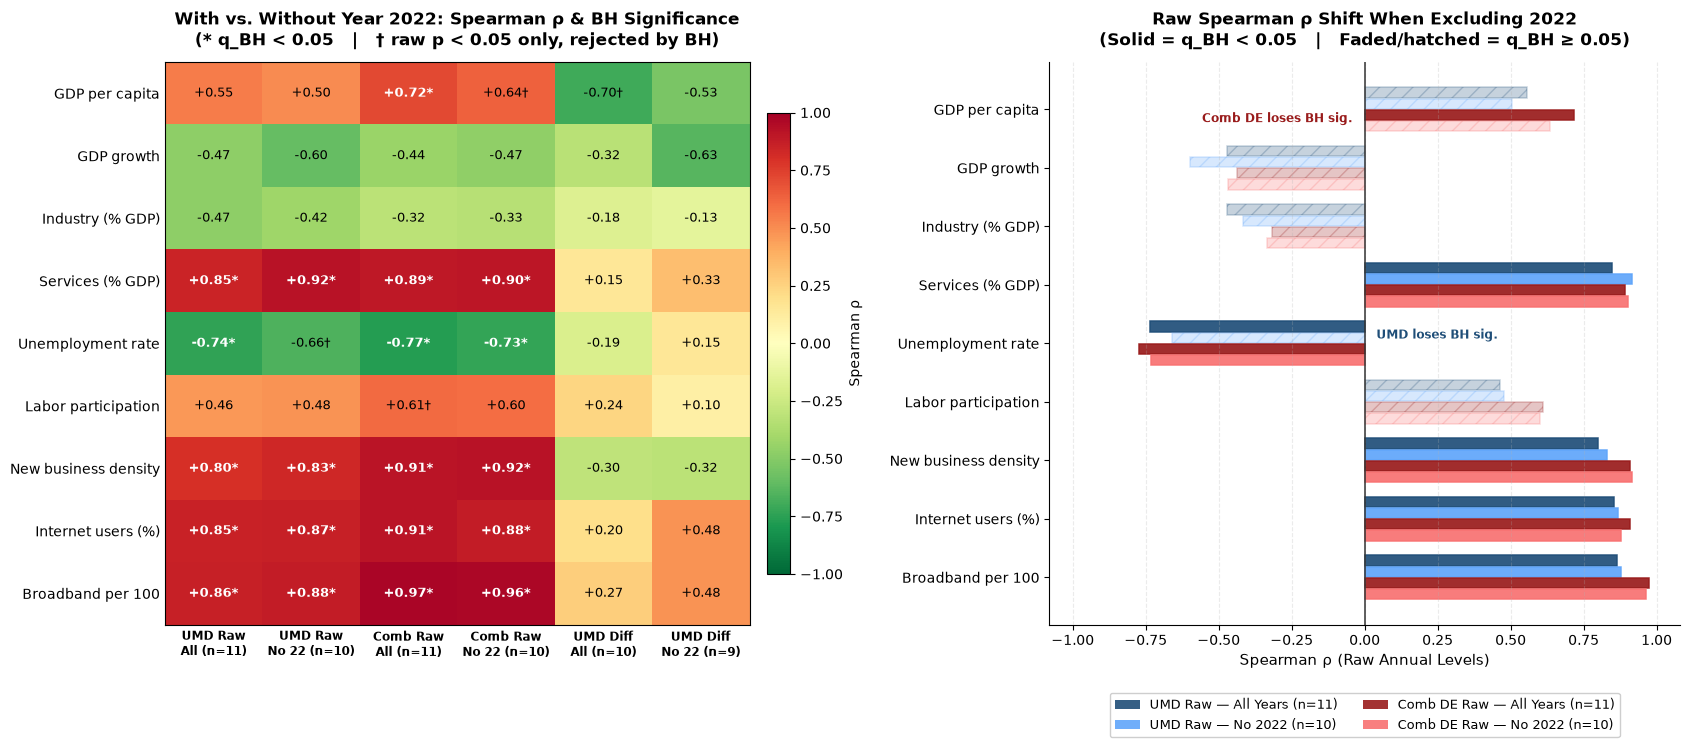

Without 2022 -> UMD Raw: 5/9 raw, 4/9 BH | Comb DE Raw: 6/9 raw, 5/9 BH | UMD Diff (n=9): 0/9 raw, 0/9 BH | Comb DE Diff (n=9): 0/9 raw, 0/9 BH


,UMD rho (All),UMD rho (No 22),UMD q_BH (All),UMD q_BH (No 22),Comb rho (All),Comb rho (No 22),Comb q_BH (All),Comb q_BH (No 22),UMD Diff rho (No 22),UMD Diff q_BH (No 22),Comb Diff rho (No 22),Comb Diff q_BH (No 22)
feature,,,,,,,,,,,,
GDP per capita,0.5545,0.5030,0.1150,0.1779,0.7182,0.6364,0.0192,0.0719,-0.5333,0.4218,0.2500,0.6641
GDP growth,-0.4727,-0.6000,0.1509,0.1000,-0.4364,-0.4667,0.2021,0.1957,-0.6333,0.4218,-0.1667,0.7518
Industry (% GDP),-0.4727,-0.4182,0.1509,0.2291,-0.3182,-0.3333,0.3403,0.3466,-0.1333,0.7980,0.3833,0.6641
Services (% GDP),0.8455,0.9152,0.0031,0.0018,0.8909,0.9030,0.0005,0.0010,0.3333,0.6096,-0.3333,0.6641
Unemployment rate,-0.7364,-0.6606,0.0176,0.0677,-0.7727,-0.7333,0.0095,0.0284,0.1500,0.7980,-0.0500,0.8984
Labor participation,0.4636,0.4788,0.1509,0.1817,0.6091,0.6000,0.0600,0.0857,0.1000,0.7980,0.2667,0.6641
New business density,0.8000,0.8303,0.0070,0.0066,0.9091,0.9152,0.0003,0.0009,-0.3167,0.6096,-0.2667,0.6641
Internet users (%),0.8545,0.8667,0.0031,0.0035,0.9091,0.8788,0.0003,0.0018,0.4833,0.4218,0.2667,0.6641
Broadband per 100,0.8636,0.8788,0.0031,0.0035,0.9727,0.9636,0.0000,0.0001,0.4833,0.4218,0.5333,0.6641


In [7]:
# Filter out 2022 from Germany's 2014-2024 series and compute differences on the remaining 10 years
deu_no22 = deu_comp[deu_comp["year"] != 2022].sort_values("year").copy()
# Note: diff() on deu_no22 bridges 2021 -> 2023 directly (n=9 transitions)
deu_no22_diff = deu_no22.set_index("year")[diff_cols].diff().dropna()

res_umd_raw_n22 = compute_spearman_bh(deu_no22, "incidents_per_100k", feat_cols, FEATURE_LABELS)
res_comb_raw_n22 = compute_spearman_bh(deu_no22, "de_combined_per_100k", feat_cols, FEATURE_LABELS)
res_umd_diff_n22 = compute_spearman_bh(deu_no22_diff, "incidents_per_100k", feat_cols, FEATURE_LABELS)
res_comb_diff_n22 = compute_spearman_bh(deu_no22_diff, "de_combined_per_100k", feat_cols, FEATURE_LABELS)

col_map_s6 = {
    "UMD Raw\nAll (n=11)": res_umd_raw,
    "UMD Raw\nNo 22 (n=10)": res_umd_raw_n22,
    "Comb Raw\nAll (n=11)": res_comb_raw,
    "Comb Raw\nNo 22 (n=10)": res_comb_raw_n22,
    "UMD Diff\nAll (n=10)": res_umd_diff,
    "UMD Diff\nNo 22 (n=9)": res_umd_diff_n22,
}
rho_s6 = pd.DataFrame({k: v["rho"] for k, v in col_map_s6.items()})
p_s6 = pd.DataFrame({k: v["p_raw"] for k, v in col_map_s6.items()})
q_s6 = pd.DataFrame({k: v["q_bh"] for k, v in col_map_s6.items()})

fig, axes = plt.subplots(
    1, 2, figsize=(17.0, 7.6), gridspec_kw={"width_ratios": [1.18, 1.05]}
)

im6 = plot_sig_heatmap(
    axes[0],
    rho_s6,
    p_s6,
    q_s6,
    "With vs. Without Year 2022: Spearman ρ & BH Significance\n(* q_BH < 0.05   |   † raw p < 0.05 only, rejected by BH)",
)
cbar6 = fig.colorbar(im6, ax=axes[0], shrink=0.82, pad=0.025)
cbar6.set_label("Spearman ρ", fontsize=10)

# Right panel: visual comparison of Raw rho shift when 2022 is dropped (UMD & Combined DE)
bar_specs_s6 = [
    ("UMD Raw — All Years (n=11)", res_umd_raw, -0.285, "#1F4E78"),
    ("UMD Raw — No 2022 (n=10)", res_umd_raw_n22, -0.095, "#60A5FA"),
    ("Comb DE Raw — All Years (n=11)", res_comb_raw, +0.095, "#991B1B"),
    ("Comb DE Raw — No 2022 (n=10)", res_comb_raw_n22, +0.285, "#F87171"),
]
for lbl, res_df, offset, color in bar_specs_s6:
    vals = res_df["rho"].values
    sigs = res_df["sig_bh"].values
    for idx in range(len(feat_names)):
        is_sig = bool(sigs[idx])
        axes[1].barh(
            y_pos[idx] + offset,
            vals[idx],
            height=bar_h,
            color=color,
            alpha=0.92 if is_sig else 0.25,
            edgecolor=color,
            linewidth=1.1,
            hatch=None if is_sig else "//",
        )
    axes[1].barh(0, 0, height=0, color=color, alpha=0.9, label=lbl)

# Highlight the two rows whose BH significance status flipped after dropping 2022
for idx, fname in enumerate(feat_names):
    if fname == "Unemployment rate":
        axes[1].text(0.04, y_pos[idx] - 0.14, "UMD loses BH sig.", fontsize=8.4, color="#1F4E78", fontweight="bold", va="center")
    elif fname == "GDP per capita":
        axes[1].text(-0.04, y_pos[idx] + 0.16, "Comb DE loses BH sig.", fontsize=8.4, color="#991B1B", fontweight="bold", ha="right", va="center")

axes[1].axvline(0, color="#333333", linewidth=1.1)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(feat_names, fontsize=10.2)
axes[1].invert_yaxis()
axes[1].set_xlim(-1.08, 1.08)
axes[1].set_xlabel("Spearman ρ (Raw Annual Levels)", fontsize=10.5)
axes[1].set_title(
    "Raw Spearman ρ Shift When Excluding 2022\n(Solid = q_BH < 0.05   |   Faded/hatched = q_BH ≥ 0.05)",
    fontsize=12.5,
    fontweight="bold",
    pad=12,
)
axes[1].grid(axis="x", alpha=0.25, linestyle="--")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=9.0, framealpha=0.95)

plt.tight_layout()
plt.show()

print(
    f"Without 2022 -> "
    f"UMD Raw: {int(res_umd_raw_n22['sig_raw'].sum())}/9 raw, {int(res_umd_raw_n22['sig_bh'].sum())}/9 BH | "
    f"Comb DE Raw: {int(res_comb_raw_n22['sig_raw'].sum())}/9 raw, {int(res_comb_raw_n22['sig_bh'].sum())}/9 BH | "
    f"UMD Diff (n=9): {int(res_umd_diff_n22['sig_raw'].sum())}/9 raw, {int(res_umd_diff_n22['sig_bh'].sum())}/9 BH | "
    f"Comb DE Diff (n=9): {int(res_comb_diff_n22['sig_raw'].sum())}/9 raw, {int(res_comb_diff_n22['sig_bh'].sum())}/9 BH"
)

summary_s6 = pd.DataFrame(
    {
        "UMD rho (All)": res_umd_raw["rho"],
        "UMD rho (No 22)": res_umd_raw_n22["rho"],
        "UMD q_BH (All)": res_umd_raw["q_bh"],
        "UMD q_BH (No 22)": res_umd_raw_n22["q_bh"],
        "Comb rho (All)": res_comb_raw["rho"],
        "Comb rho (No 22)": res_comb_raw_n22["rho"],
        "Comb q_BH (All)": res_comb_raw["q_bh"],
        "Comb q_BH (No 22)": res_comb_raw_n22["q_bh"],
        "UMD Diff rho (No 22)": res_umd_diff_n22["rho"],
        "UMD Diff q_BH (No 22)": res_umd_diff_n22["q_bh"],
        "Comb Diff rho (No 22)": res_comb_diff_n22["rho"],
        "Comb Diff q_BH (No 22)": res_comb_diff_n22["q_bh"],
    }
).round(4)
display(summary_s6)